In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)


import numpy as np
import tensorflow as tf
from tqdm import tqdm

from data_loaders.data_loader_patches import DataLoaderPatches
import project_images_loader as pil
import utils.functions as fc
import utils.nifti_functions as nfc
import utils.util as util
import utils.visualization as vis
import matplotlib.pyplot as plt

from generator import MetamorphicGenerator
from discriminator import MetamorphicDiscriminator

import utils.patches_controller as patches_controller


# tf.config.set_visible_devices([], 'GPU')
# os.environ["CUDA_VISIBLE_DEVICES"]="-1"




TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.12.0 and strictly below 2.15.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.10.1 and is not supported. 
Some things might work, some things might not.
If you were to encounter a bug, do not file an issue.
If you want to make sure you're using a tested and supported configuration, either change the TensorFlow version or the TensorFlow Addons's version. 
You can find the compatibility matrix in TensorFlow Addon's readme:
https://github.com/tensorflow/

In [2]:
input_shape = (192,224,192)

inital_lr = 1e-4

# g_optimizer = tf.keras.optimizers.Adam(inital_lr)
# d_optimizer = tf.keras.optimizers.Adam(inital_lr)

D_h4 = MetamorphicDiscriminator()

checkpoint_dir = f"{current_path}/models/training_checkpoints/"
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(
                                # generator_optimizer=g_optimizer,
                                # discriminator_optimizer=d_optimizer,
                                # generator=G,
                                # discriminator=D
                                D_h4 = D_h4
                                )
# checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

matching_ids = pil.get_matching_ids()

In [3]:
def save_image(id, img_gen, checkpoint_index):
    img_original, affine = pil.load_preprocessed_image(3, id, absolute=True)
    img_to_save = np.zeros_like(img_original)
    img_to_save[:img_gen.shape[0], :img_gen.shape[1], :img_gen.shape[2]] = img_gen
    nfc.save_nifti(img_to_save.astype(np.float32), affine, f"{current_path}/images/first_results/D_{id}_CHECK_{checkpoint_index}.nii.gz")


def generate_image_step(img_org, G, patch_size, patch_step, batch_size=20):
    img_patches = patches_controller.extract_patches(img_org, patch_shape=patch_size, extraction_step=patch_step).astype(np.float32)
    gen_patches = np.zeros_like(img_patches)

    for i in tqdm(range(0, len(img_patches), batch_size)):
        patches_batch = np.expand_dims(img_patches[i:min(i+batch_size, len(img_patches))], axis=-1)
        gen_result = G(patches_batch, training=False)
        gen_patches[i:min(i+batch_size, len(img_patches))] = gen_result[-1][..., 0]

    gen_image = patches_controller.perform_voting(gen_patches, 
                                                  patch_shape=patch_size, 
                                                  expected_shape=img_org.shape, 
                                                  extraction_step=patch_step,
                                                  window_sep=patch_step)
    return gen_image


def generate_image(id, G, patch_size, patch_step, backward=False):
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    if backward:
        img_gen = generate_image_step(img_hunt4, G, patch_size=patch_size, patch_step=patch_step)
    else:
        img_gen = generate_image_step(img_hunt3, G, patch_size=patch_size, patch_step=patch_step)
   
    # vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4)
    # vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h3)
    return img_hunt3, img_hunt4, img_gen


100%|██████████| 8/8 [01:28<00:00, 11.12s/it]


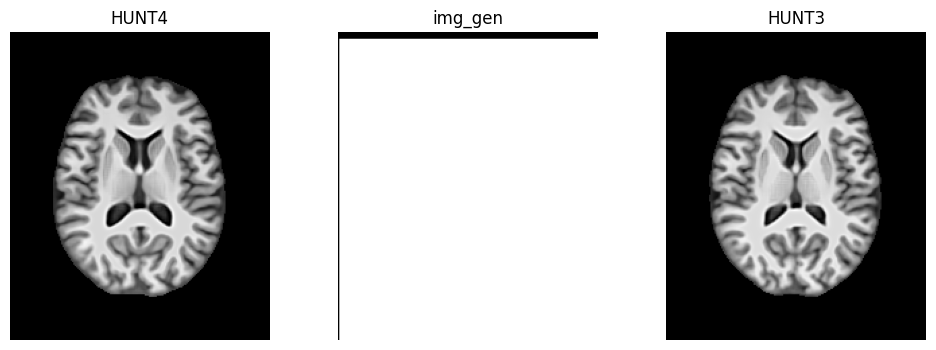

In [4]:
# %matplotlib widget
# %matplotlib tk
# %matplotlib inline

current_plane = 116



# id_indexs = [301, 302, 303, 304, 305]
# id_indexs = [0, 301, 302, 303]
id_indexs = [302]

images_list = []
# for checkpoint_index in range(3, 33, 2):
for checkpoint_index in [31]:
    for id_index in id_indexs:
        id = matching_ids[id_index]
        checkpoint.restore(f"{checkpoint_dir}/ckpt-{checkpoint_index}")
        img_hunt3, img_hunt4, img_gen = generate_image(id, D_h4, patch_size=(64,64,64), patch_step=(32,32,32), backward=False)

        # images_list.append([img_hunt3, img_hunt4, img_gen])
        vis.shows_3_images(img_hunt3, img_hunt4, img_gen)
        # vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")

        # save image
        save_image(id, img_gen, checkpoint_index)




In [5]:
for images in images_list:
    vis.shows_3_images(images[0], images[1], images[2], current_plane=116)

In [6]:
for images in images_list:
    vis.shows_3_images(images[0], images[1], images[2], current_plane=116)

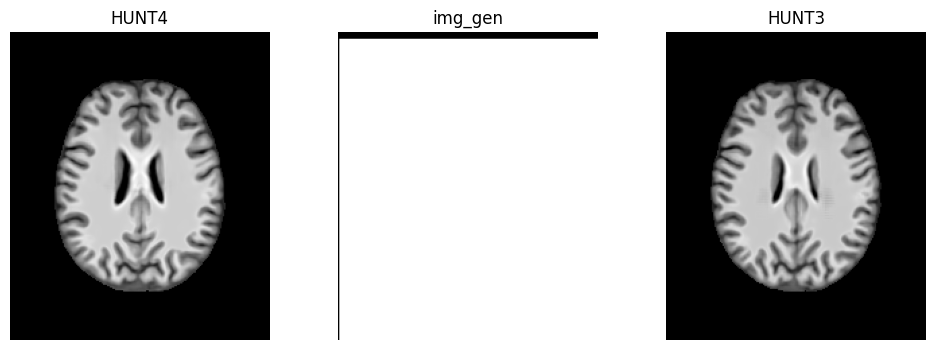

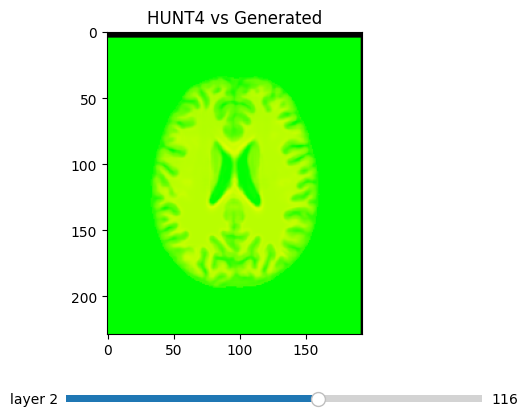

In [7]:
vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=118)
vis.show_rg_img(img_hunt4, img_gen, "HUNT4 vs Generated")
